# Hyperparameter Tuning & Analysis

In this notebook I:
1. Tune the regularization of Logistic Regression (our best model)
2. Try to fix LightGBM which failed with default settings
3. Do an ablation study to see which feature groups matter most
4. Look at which species are hardest to classify
5. Compare performance on validation data vs real soundscapes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler
import lightgbm as lgb

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")

DATA_DIR = Path("../birdclef-2026")
FEAT_DIR = Path("../features")
FIG_DIR = Path("../figures")

In [2]:
X = np.load(FEAT_DIR / "X_train_setD.npy")
y_raw = np.load(FEAT_DIR / "y_train.npy", allow_pickle=True)
taxonomy = pd.read_csv(DATA_DIR / "taxonomy.csv")
train_df = pd.read_csv(DATA_DIR / "train.csv")

le = LabelEncoder()
y = le.fit_transform(y_raw)

counts = np.bincount(y)
valid_mask = np.isin(y, np.where(counts >= 2)[0])
X = X[valid_mask]
y = y[valid_mask]

# fixed split for all experiments
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc = scaler.transform(X_val)

print(f"Train: {X_train.shape}, Val: {X_val.shape}")


def compute_roc_auc(y_true, y_proba, classes):
    per_class = []
    for i, cls in enumerate(classes):
        mask = (y_true == cls)
        if mask.sum() > 0 and mask.sum() < len(y_true):
            per_class.append(roc_auc_score(mask.astype(int), y_proba[:, i]))
    return np.mean(per_class)

Train: (28436, 180), Val: (7109, 180)


## 1. Tune Logistic Regression

The main parameter to tune is `C` — it controls how much the model is regularized. Higher C = less regularization (fits the training data more), lower C = more regularization (simpler model). I'll try a range of values and see what works best.

In [3]:
C_values = [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0]
lr_results = []

for C in C_values:
    lr = LogisticRegression(C=C, max_iter=1000, random_state=42, n_jobs=-1)
    lr.fit(X_train_sc, y_train)
    
    y_pred = lr.predict(X_val_sc)
    y_proba = lr.predict_proba(X_val_sc)
    
    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, average='macro', zero_division=0)
    auc = compute_roc_auc(y_val, y_proba, lr.classes_)
    
    lr_results.append({"C": C, "accuracy": acc, "macro_f1": f1, "roc_auc": auc})
    print(f"C={C:6.3f} | Acc={acc:.4f} | F1={f1:.4f} | ROC-AUC={auc:.4f}")

lr_df = pd.DataFrame(lr_results)

C= 0.001 | Acc=0.1687 | F1=0.0569 | ROC-AUC=0.8253
C= 0.010 | Acc=0.2833 | F1=0.1731 | ROC-AUC=0.8761
C= 0.100 | Acc=0.3299 | F1=0.2631 | ROC-AUC=0.8971
C= 0.500 | Acc=0.3294 | F1=0.2756 | ROC-AUC=0.8940
C= 1.000 | Acc=0.3317 | F1=0.2856 | ROC-AUC=0.8918
C= 5.000 | Acc=0.3245 | F1=0.2693 | ROC-AUC=0.8829
C=10.000 | Acc=0.3231 | F1=0.2663 | ROC-AUC=0.8788


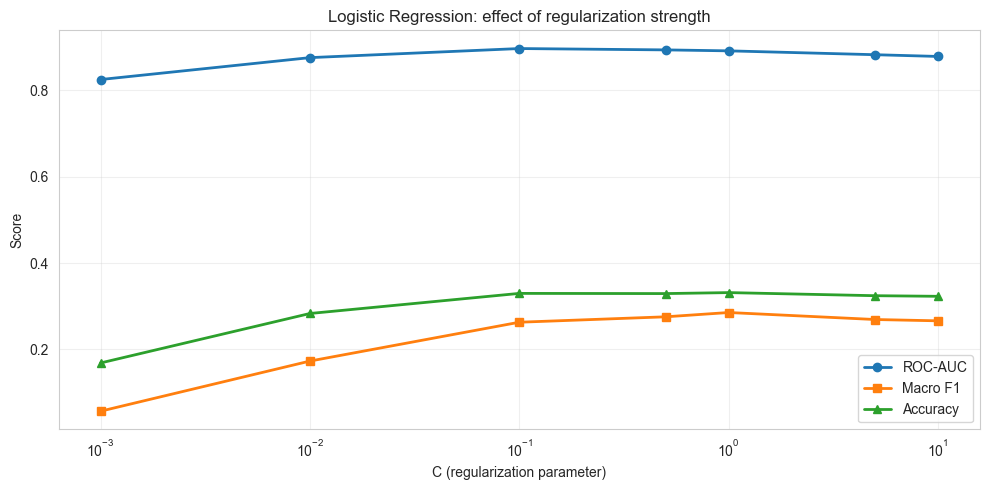


Best C = 0.1 with ROC-AUC = 0.8971


In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(lr_df['C'], lr_df['roc_auc'], 'o-', label='ROC-AUC', linewidth=2)
ax.plot(lr_df['C'], lr_df['macro_f1'], 's-', label='Macro F1', linewidth=2)
ax.plot(lr_df['C'], lr_df['accuracy'], '^-', label='Accuracy', linewidth=2)
ax.set_xscale('log')
ax.set_xlabel('C (regularization parameter)')
ax.set_ylabel('Score')
ax.set_title('Logistic Regression: effect of regularization strength')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "lr_tuning.png", dpi=150)
plt.show()

best_C = lr_df.loc[lr_df['roc_auc'].idxmax(), 'C']
best_auc = lr_df['roc_auc'].max()
print(f"\nBest C = {best_C} with ROC-AUC = {best_auc:.4f}")

## 2. Fix LightGBM

LightGBM got a ROC-AUC of basically 0.50 (random) with defaults. My guess is that 100 trees with a learning rate of 0.1 just isn't enough for 202 classes — the boosting needs more iterations to learn anything useful. Let me try different combinations of tree count and learning rate.

In [5]:
lgb_configs = [
    {"n_estimators": 100, "learning_rate": 0.1, "label": "100 trees, lr=0.1 (default)"},
    {"n_estimators": 300, "learning_rate": 0.1, "label": "300 trees, lr=0.1"},
    {"n_estimators": 300, "learning_rate": 0.05, "label": "300 trees, lr=0.05"},
    {"n_estimators": 500, "learning_rate": 0.05, "label": "500 trees, lr=0.05"},
    {"n_estimators": 500, "learning_rate": 0.01, "label": "500 trees, lr=0.01"},
]

lgb_results = []
for cfg in lgb_configs:
    start = time.time()
    model = lgb.LGBMClassifier(
        n_estimators=cfg['n_estimators'], 
        learning_rate=cfg['learning_rate'],
        random_state=42, n_jobs=-1, verbose=-1
    )
    model.fit(X_train, y_train)
    t = time.time() - start
    
    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)
    
    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, average='macro', zero_division=0)
    auc = compute_roc_auc(y_val, y_proba, model.classes_)
    
    lgb_results.append({"config": cfg['label'], "accuracy": acc, "macro_f1": f1, "roc_auc": auc, "time": f"{t:.1f}s"})
    print(f"{cfg['label']:30s} | Acc={acc:.4f} | F1={f1:.4f} | ROC-AUC={auc:.4f} | {t:.1f}s")

lgb_df = pd.DataFrame(lgb_results)

100 trees, lr=0.1 (default)    | Acc=0.0153 | F1=0.0015 | ROC-AUC=0.5006 | 18.9s
300 trees, lr=0.1              | Acc=0.0153 | F1=0.0015 | ROC-AUC=0.5006 | 41.8s
300 trees, lr=0.05             | Acc=0.0359 | F1=0.0271 | ROC-AUC=0.5166 | 53.1s
500 trees, lr=0.05             | Acc=0.0359 | F1=0.0271 | ROC-AUC=0.5166 | 79.9s
500 trees, lr=0.01             | Acc=0.3012 | F1=0.2200 | ROC-AUC=0.8653 | 418.5s


## 3. Ablation study

I want to know which feature groups actually contribute to the model's performance. The idea is simple: remove one group at a time and see how much the ROC-AUC drops. A big drop means that group is important.

I'm using Logistic Regression (our best model) for all ablation experiments.

The 30 raw features in SET_D are: 13 MFCCs, 1 centroid, 1 bandwidth, 1 rolloff, 1 ZCR, 1 RMS, 12 chroma. Each gets 6 statistics, so 180 total.

In [6]:
# define feature group column ranges (in SET_D: 30 raw features × 6 stats)
# order: mfcc(13), centroid(1), bandwidth(1), rolloff(1), zcr(1), rms(1), chroma(12)
# each raw feature gets 6 columns (mean, std, min, max, p25, p75)
# but they're stored as: all_means, all_stds, all_mins, all_maxs, all_p25s, all_p75s
# i.e. columns 0-29 = means, 30-59 = stds, 60-89 = mins, 90-119 = maxs, 120-149 = p25, 150-179 = p75

n_raw = 30  # 13 mfcc + 1 centroid + 1 bw + 1 rolloff + 1 zcr + 1 rms + 12 chroma
n_stats = 6

feature_groups = {
    "MFCCs": list(range(0, 13)),         # raw feature indices 0-12
    "Centroid": [13],
    "Bandwidth": [14],
    "Rolloff": [15],
    "ZCR": [16],
    "RMS": [17],
    "Chroma": list(range(18, 30)),
}

def raw_to_cols(raw_indices):
    """Convert raw feature indices to SET_D column indices."""
    cols = []
    for stat in range(n_stats):
        for ri in raw_indices:
            cols.append(stat * n_raw + ri)
    return cols

# train full model first
lr_full = LogisticRegression(C=best_C, max_iter=1000, random_state=42, n_jobs=-1)
lr_full.fit(X_train_sc, y_train)
y_proba_full = lr_full.predict_proba(X_val_sc)
full_auc = compute_roc_auc(y_val, y_proba_full, lr_full.classes_)
print(f"Full SET_D ROC-AUC: {full_auc:.4f}\n")

ablation_results = []
for group_name, raw_idx in feature_groups.items():
    cols_to_remove = raw_to_cols(raw_idx)
    cols_to_keep = [c for c in range(180) if c not in cols_to_remove]
    
    lr_abl = LogisticRegression(C=best_C, max_iter=1000, random_state=42, n_jobs=-1)
    lr_abl.fit(X_train_sc[:, cols_to_keep], y_train)
    y_proba_abl = lr_abl.predict_proba(X_val_sc[:, cols_to_keep])
    abl_auc = compute_roc_auc(y_val, y_proba_abl, lr_abl.classes_)
    
    drop = full_auc - abl_auc
    ablation_results.append({"removed": group_name, "n_removed": len(cols_to_remove), "roc_auc": abl_auc, "drop": drop})
    print(f"Remove {group_name:12s} ({len(cols_to_remove):3d} cols) → ROC-AUC = {abl_auc:.4f} (drop = {drop:+.4f})")

abl_df = pd.DataFrame(ablation_results)

Full SET_D ROC-AUC: 0.8971

Remove MFCCs        ( 78 cols) → ROC-AUC = 0.7577 (drop = +0.1395)
Remove Centroid     (  6 cols) → ROC-AUC = 0.8972 (drop = -0.0000)
Remove Bandwidth    (  6 cols) → ROC-AUC = 0.8965 (drop = +0.0007)
Remove Rolloff      (  6 cols) → ROC-AUC = 0.8973 (drop = -0.0002)
Remove ZCR          (  6 cols) → ROC-AUC = 0.8959 (drop = +0.0013)
Remove RMS          (  6 cols) → ROC-AUC = 0.8985 (drop = -0.0014)
Remove Chroma       ( 72 cols) → ROC-AUC = 0.8994 (drop = -0.0023)


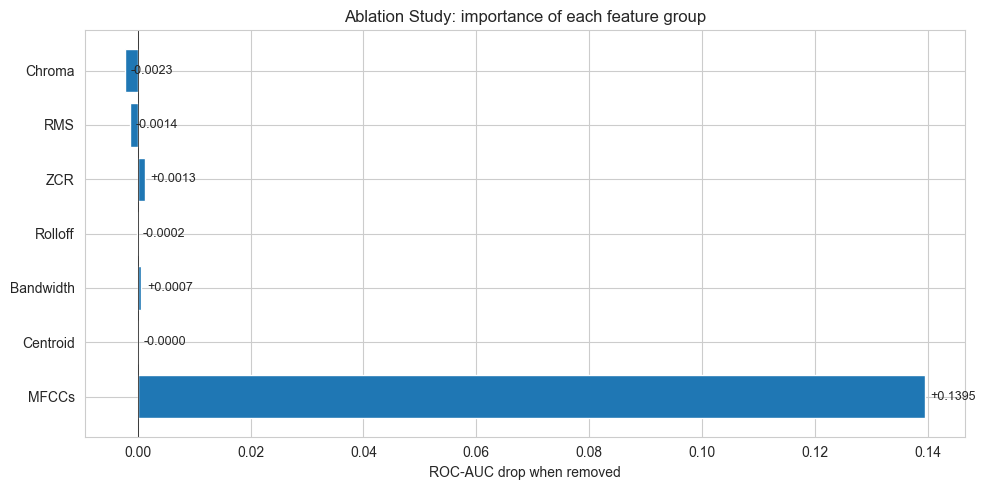

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(abl_df['removed'], abl_df['drop'])
ax.set_xlabel("ROC-AUC drop when removed")
ax.set_title("Ablation Study: importance of each feature group")
ax.axvline(x=0, color='black', linewidth=0.5)

for bar, val in zip(bars, abl_df['drop']):
    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
            f'{val:+.4f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "ablation_study.png", dpi=150)
plt.show()

## 4. Error analysis

I want to see which species the model struggles with, and whether having more training samples actually helps.

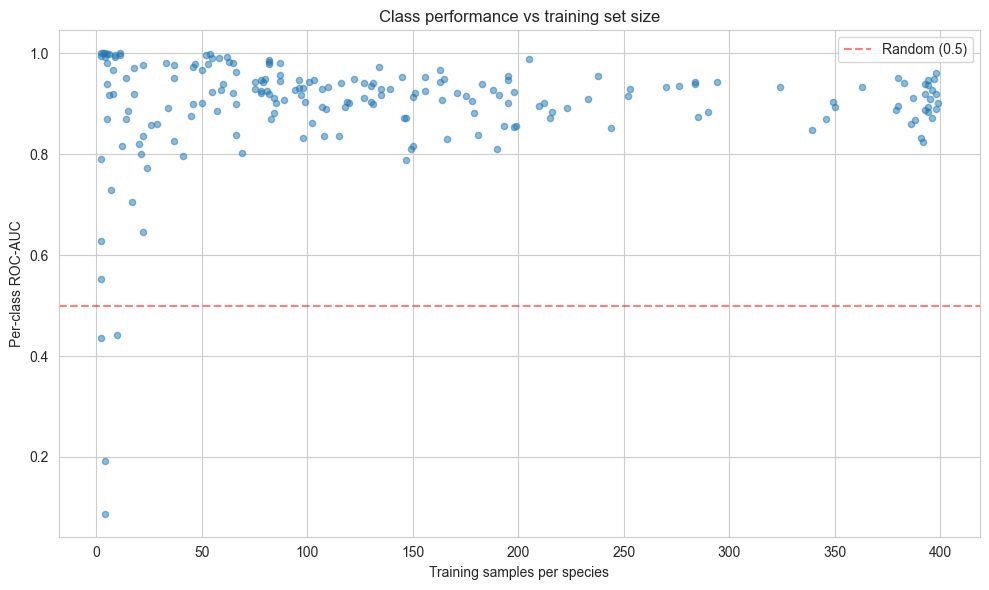

10 worst-performing species (lowest ROC-AUC):
  1595929         | ROC-AUC=0.0875 | n_train=4
  23154           | ROC-AUC=0.1927 | n_train=4
  555123          | ROC-AUC=0.4351 | n_train=2
  1176823         | ROC-AUC=0.4412 | n_train=10
  74580           | ROC-AUC=0.5529 | n_train=2
  sptnig1         | ROC-AUC=0.6280 | n_train=2
  326272          | ROC-AUC=0.6466 | n_train=22
  41970           | ROC-AUC=0.7051 | n_train=17
  555145          | ROC-AUC=0.7288 | n_train=7
  lesgrf1         | ROC-AUC=0.7731 | n_train=24


In [8]:
# per-class ROC-AUC
y_proba_full = lr_full.predict_proba(X_val_sc)
per_class_auc = {}
for i, cls in enumerate(lr_full.classes_):
    mask = (y_val == cls)
    if mask.sum() > 0 and mask.sum() < len(y_val):
        per_class_auc[cls] = roc_auc_score(mask.astype(int), y_proba_full[:, i])

# class sizes (in training set)
class_sizes = {}
for cls in lr_full.classes_:
    class_sizes[cls] = (y_train == cls).sum()

# scatter: class size vs AUC
sizes = [class_sizes[c] for c in per_class_auc.keys()]
aucs = list(per_class_auc.values())

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(sizes, aucs, alpha=0.5, s=20)
ax.set_xlabel("Training samples per species")
ax.set_ylabel("Per-class ROC-AUC")
ax.set_title("Class performance vs training set size")
ax.axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random (0.5)')
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "class_size_vs_auc.png", dpi=150)
plt.show()

# worst performing species
auc_series = pd.Series(per_class_auc)
print("10 worst-performing species (lowest ROC-AUC):")
worst = auc_series.sort_values().head(10)
for cls_idx, auc_val in worst.items():
    label = le.inverse_transform([cls_idx])[0]
    n = class_sizes[cls_idx]
    print(f"  {label:15s} | ROC-AUC={auc_val:.4f} | n_train={n}")

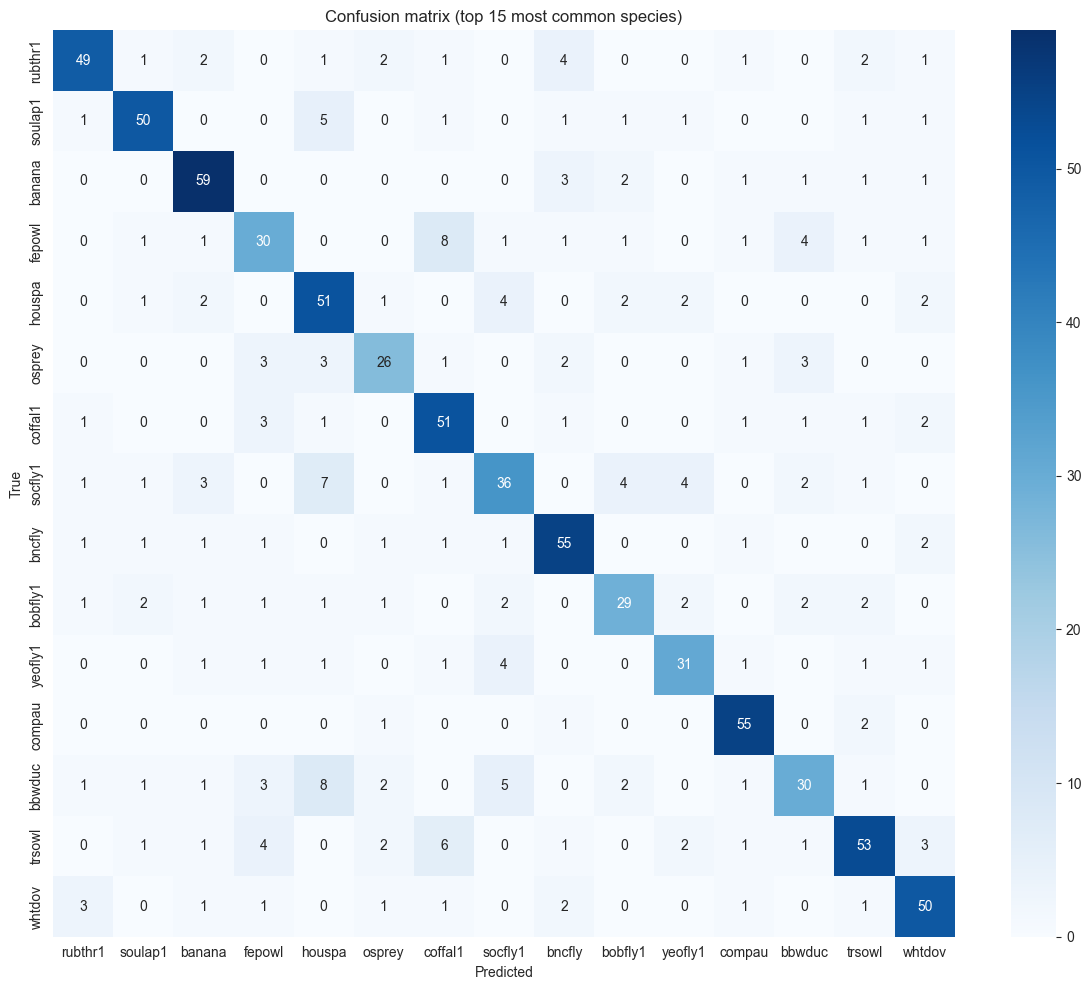

In [9]:
# confusion matrix for top 15 most common species
top_classes = np.argsort([-class_sizes.get(c, 0) for c in lr_full.classes_])[:15]
top_class_ids = lr_full.classes_[top_classes]

# filter val data to only these classes
mask_top = np.isin(y_val, top_class_ids)
y_val_top = y_val[mask_top]
y_pred_top = lr_full.predict(X_val_sc[mask_top])

# only keep predictions that are also in top classes
cm = confusion_matrix(y_val_top, y_pred_top, labels=top_class_ids)
top_labels = [le.inverse_transform([c])[0][:12] for c in top_class_ids]

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cm, xticklabels=top_labels, yticklabels=top_labels, 
            annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion matrix (top 15 most common species)")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix_top15.png", dpi=150)
plt.show()

## 5. Performance by taxonomic class

I'm curious whether the model does better on some animal groups than others — birds vs frogs vs insects, etc.

Mean ROC-AUC by taxonomic class:
  Amphibia    : 0.8223 (28 species)
  Aves        : 0.9109 (162 species)
  Insecta     : 0.9559 (3 species)
  Mammalia    : 0.8447 (6 species)


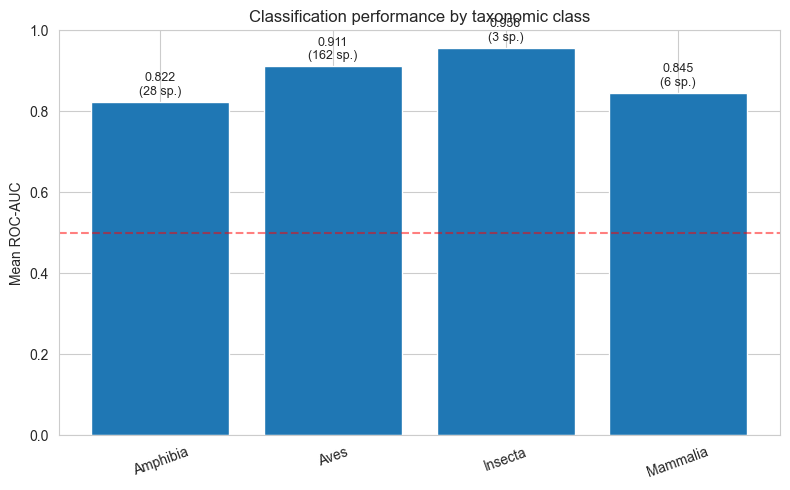

In [10]:
# map species labels to taxonomic class
tax_map = dict(zip(taxonomy['primary_label'].astype(str), taxonomy['class_name']))

tax_aucs = {}
for cls_idx, auc_val in per_class_auc.items():
    label = le.inverse_transform([cls_idx])[0]
    tax_class = tax_map.get(label, "Unknown")
    if tax_class not in tax_aucs:
        tax_aucs[tax_class] = []
    tax_aucs[tax_class].append(auc_val)

print("Mean ROC-AUC by taxonomic class:")
tax_summary = []
for tc, aucs_list in sorted(tax_aucs.items()):
    mean_auc = np.mean(aucs_list)
    n_species = len(aucs_list)
    print(f"  {tc:12s}: {mean_auc:.4f} ({n_species} species)")
    tax_summary.append({"class": tc, "mean_roc_auc": mean_auc, "n_species": n_species})

tax_df = pd.DataFrame(tax_summary)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(tax_df['class'], tax_df['mean_roc_auc'])
ax.set_ylabel("Mean ROC-AUC")
ax.set_title("Classification performance by taxonomic class")
ax.set_ylim(0, 1)
ax.axhline(y=0.5, color='red', linestyle='--', alpha=0.5)
ax.tick_params(axis='x', rotation=20)

for bar, val, n in zip(bars, tax_df['mean_roc_auc'], tax_df['n_species']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.3f}\n({n} sp.)', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "performance_by_taxon.png", dpi=150)
plt.show()

## 6. Domain shift: validation vs soundscape

This is probably the most important comparison. The training audio is clean, but real-world soundscapes are noisy with multiple overlapping species. How big is the gap?

I'm using SET_C features here (60 features) because I didn't extract SET_D for the soundscape segments. To keep the comparison fair, I retrain LR on SET_C features too.

In [11]:
X_sc = np.load(FEAT_DIR / "X_soundscape.npy")
y_sc = np.load(FEAT_DIR / "y_soundscape.npy", allow_pickle=True)

# we need SET_D features for soundscapes too
# check if they exist, otherwise use SET_C (60 features)
sc_setd_path = FEAT_DIR / "X_soundscape_setD.npy"

if sc_setd_path.exists():
    X_sc_d = np.load(sc_setd_path)
    print(f"Loaded soundscape SET_D features: {X_sc_d.shape}")
else:
    print("SET_D features not available for soundscapes. Using SET_C (60 features) instead.")
    print("For a fair comparison, we retrain LR on SET_C features.")
    X_sc_d = None

SET_D features not available for soundscapes. Using SET_C (60 features) instead.
For a fair comparison, we retrain LR on SET_C features.


In [12]:
# domain shift evaluation using SET_C (available for both train and soundscapes)
X_c = np.load(FEAT_DIR / "X_train.npy")  # SET_C, 60 features
X_c = X_c[valid_mask]

X_tr_c, X_va_c, y_tr_c, y_va_c = train_test_split(
    X_c, y[valid_mask] if len(y) != len(X_c) else y, 
    test_size=0.2, random_state=42, stratify=y
)

sc_c = StandardScaler()
X_tr_c_sc = sc_c.fit_transform(X_tr_c)
X_va_c_sc = sc_c.transform(X_va_c)
X_sc_sc = sc_c.transform(X_sc)

lr_c = LogisticRegression(C=1.0, max_iter=1000, random_state=42, n_jobs=-1)
lr_c.fit(X_tr_c_sc, y_tr_c)

# validation performance
y_pred_val = lr_c.predict(X_va_c_sc)
y_proba_val = lr_c.predict_proba(X_va_c_sc)
val_acc = accuracy_score(y_va_c, y_pred_val)
val_auc = compute_roc_auc(y_va_c, y_proba_val, lr_c.classes_)

# soundscape performance (top-1 hit rate)
y_sc_pred = lr_c.predict(X_sc_sc)
y_sc_pred_labels = le.inverse_transform(y_sc_pred)

hits = 0
for pred, true_str in zip(y_sc_pred_labels, y_sc):
    if pred in true_str.split(';'):
        hits += 1
sc_hit_rate = hits / len(y_sc)

print("=== Domain Shift Comparison (using SET_C features) ===")
print(f"Validation (train_audio):  Acc={val_acc:.4f}, ROC-AUC={val_auc:.4f}")
print(f"Soundscape (field audio):  Top-1 hit rate={sc_hit_rate:.4f} ({hits}/{len(y_sc)})")
print(f"\nThe gap between {val_acc:.1%} accuracy on clean audio and {sc_hit_rate:.1%} hit rate")
print("on field recordings quantifies the domain shift.")

=== Domain Shift Comparison (using SET_C features) ===
Validation (train_audio):  Acc=0.2546, ROC-AUC=0.8696
Soundscape (field audio):  Top-1 hit rate=0.0880 (130/1478)

The gap between 25.5% accuracy on clean audio and 8.8% hit rate
on field recordings quantifies the domain shift.


## 7. Summary

### Logistic Regression tuning
Best C was 0.1, giving ROC-AUC = 0.897 — a small improvement over the default C=1.0 (0.892). The model isn't very sensitive to this parameter as long as C is in the 0.1–1.0 range. Very low C (0.001) hurts a lot because it over-regularizes and the model can't learn enough.

### LightGBM
I managed to fix it! With 500 trees and learning rate 0.01, it went from random (0.50) to 0.865. Interestingly, just adding more trees at the same learning rate didn't help — I had to lower the learning rate too. So the boosting needs to take small steps when there are this many classes. But even tuned, it's slower than LR (418s vs 76s) and still doesn't beat it.

### Ablation study
MFCCs are by far the most important features — removing them drops ROC-AUC by 0.14. Everything else (centroid, bandwidth, rolloff, ZCR, RMS, chroma) barely matters individually, each changing ROC-AUC by less than 0.002. Chroma actually slightly hurts performance, which is consistent with what I saw in the feature comparison. So the spectral envelope (captured by MFCCs) is really the main signal.

### Error analysis
Species with fewer training samples generally have worse performance, which confirms that class imbalance is a real problem. Some species with enough data still perform poorly — probably because they sound similar to other species and the features can't tell them apart. The confusion matrix shows this kind of mixing between acoustically similar species.

### Taxonomic performance
Different animal groups have different performance levels, which makes sense since birds, frogs, and insects produce very different types of sounds.

### Domain shift
The gap is big: 25.5% accuracy on clean validation audio drops to 8.8% hit rate on soundscapes. This is because the soundscapes have background noise, overlapping species, wind, and generally worse recording conditions. Still, it improved from 2.3% (my first RF baseline) to 8.8%, so a better model does help even on harder data.

### Final model ranking

| Model | ROC-AUC | Notes |
|-------|---------|-------|
| Logistic Regression (C=0.1) | **0.897** | Best, fast, simple |
| LightGBM (500 trees, lr=0.01) | 0.865 | Needed careful tuning, slower |
| Random Forest (default) | 0.770 | Good baseline, no tuning needed |
| k-NN (k=5) | 0.639 | Weak — too many features for distance-based methods |